# Assignment-4 — Clustering on Iris and Wine

**Name:** Anuska Nath

**Class Roll No:** 002311001003

Import all libraries.

In [ ]:
import numpy as np, pandas as pd, warnings
import matplotlib.pyplot as plt
from itertools import product
from scipy.optimize import linear_sum_assignment
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.datasets import load_iris, load_wine
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, OPTICS
from sklearn.metrics import (rand_score, adjusted_rand_score, mutual_info_score,
                             adjusted_mutual_info_score, normalized_mutual_info_score,
                             silhouette_score, calinski_harabasz_score, davies_bouldin_score)
from sklearn.metrics.pairwise import euclidean_distances

warnings.filterwarnings("ignore")
SEED = 42
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)

## 1. Load the datasets and preprocess


In [ ]:
def load(name):
    d = load_iris() if name == "Iris" else load_wine()
    X = d.data
    y_names = np.array(d.target_names)[d.target]          # class *names*
    y = LabelEncoder().fit_transform(y_names)             # names -> 0,1,2,...
    Xs = StandardScaler().fit_transform(X)
    return X, Xs, y, d.feature_names, list(d.target_names)

DATA = {}
for nm in ["Iris", "Wine"]:
    X, Xs, y, feats, cls = load(nm)
    DATA[nm] = dict(X=X, Xs=Xs, y=y, k=len(np.unique(y)))
    print(f"{nm}: {X.shape[0]} samples, {X.shape[1]} features, classes {cls} -> {sorted(set(y))}")

Iris: 150 samples, 4 features, classes [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')] -> [np.int64(0), np.int64(1), np.int64(2)]
Wine: 178 samples, 13 features, classes [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')] -> [np.int64(0), np.int64(1), np.int64(2)]


##  Evaluation helper functions


In [ ]:
def sse_ssb(X, labels):
    """SSE = sum ||x - c_k||^2 (cohesion).  SSB = sum n_k ||c_k - c||^2 (separation)."""
    m = X.mean(axis=0); sse = ssb = 0.0
    for k in np.unique(labels):
        P = X[labels == k]; c = P.mean(axis=0)
        sse += ((P - c) ** 2).sum()
        ssb += len(P) * ((c - m) ** 2).sum()
    return sse, ssb

def cluster_accuracy(y, labels):
    """Best one-to-one cluster->class mapping (Hungarian). Noise (-1) never matches."""
    cl = [c for c in np.unique(labels) if c != -1]; cs = np.unique(y)
    M = np.zeros((len(cl), len(cs)))
    for i, c in enumerate(cl):
        for j, s in enumerate(cs):
            M[i, j] = np.sum((labels == c) & (y == s))
    r, c_ = linear_sum_assignment(-M)
    return M[r, c_].sum() / len(y)

def evaluate(X, y, labels):
    out = dict(Rand=rand_score(y, labels), ARI=adjusted_rand_score(y, labels),
               MI=mutual_info_score(y, labels), AMI=adjusted_mutual_info_score(y, labels),
               NMI=normalized_mutual_info_score(y, labels))
    mask = labels != -1                                   # drop noise for internal metrics
    Xm, lm = X[mask], labels[mask]
    if len(np.unique(lm)) > 1:
        out.update(Silhouette=silhouette_score(Xm, lm), CH=calinski_harabasz_score(Xm, lm),
                   DB=davies_bouldin_score(Xm, lm))
        out["SSE"], out["SSB"] = sse_ssb(Xm, lm)
    else:
        out.update(Silhouette=np.nan, CH=np.nan, DB=np.nan, SSE=np.nan, SSB=np.nan)
    out["Accuracy(%)"] = 100 * cluster_accuracy(y, labels)
    out["#Clusters"] = len(np.unique(lm)); out["#Noise"] = int((~mask).sum())
    return out

def table(rows):
    return pd.DataFrame(rows).T.round(4)

## 3. Partition based clustering


In [ ]:
def kmeanspp_init(X, k, rng):
    C = [X[rng.integers(len(X))]]
    for _ in range(k - 1):
        d2 = np.min(((X[:, None, :] - np.array(C)[None]) ** 2).sum(-1), axis=1)
        C.append(X[rng.choice(len(X), p=d2 / d2.sum())])
    return np.array(C)

def my_kmeans(X, k, init="kmeans++", n_init=10, max_iter=300, seed=SEED):
    rng = np.random.default_rng(seed); best = None
    for _ in range(n_init):
        C = kmeanspp_init(X, k, rng) if init == "kmeans++" else X[rng.choice(len(X), k, replace=False)]
        for _ in range(max_iter):
            lab = ((X[:, None, :] - C[None]) ** 2).sum(-1).argmin(1)
            newC = np.array([X[lab == j].mean(0) if np.any(lab == j) else C[j] for j in range(k)])
            if np.allclose(newC, C): break
            C = newC
        sse = sum(((X[lab == j] - C[j]) ** 2).sum() for j in range(k))
        if best is None or sse < best[0]: best = (sse, lab.copy(), C.copy())
    return best[1], best[2]

def bisecting_kmeans(X, k, n_trials=10, seed=SEED):
    labels = np.zeros(len(X), dtype=int)
    while len(np.unique(labels)) < k:
        # pick the cluster with the largest SSE
        ids = np.unique(labels)
        sses = [((X[labels == i] - X[labels == i].mean(0)) ** 2).sum() for i in ids]
        target = ids[int(np.argmax(sses))]
        idx = np.where(labels == target)[0]
        sub, _ = my_kmeans(X[idx], 2, init="kmeans++", n_init=n_trials, seed=seed)
        labels[idx[sub == 1]] = labels.max() + 1          # new cluster id for one half
    return labels

def pam(X, k, max_iter=100):
    D = euclidean_distances(X); n = len(X)
    # BUILD: first medoid minimises total distance, others give greatest cost reduction
    med = [int(D.sum(1).argmin())]
    while len(med) < k:
        cur = D[:, med].min(1); best, bj = None, None
        for j in range(n):
            if j in med: continue
            gain = np.maximum(cur - D[:, j], 0).sum()
            if best is None or gain > best: best, bj = gain, j
        med.append(bj)
    cost = D[:, med].min(1).sum()
    # SWAP
    for _ in range(max_iter):
        improved = False
        for i in range(k):
            for h in range(n):
                if h in med: continue
                trial = med.copy(); trial[i] = h
                c = D[:, trial].min(1).sum()
                if c < cost - 1e-12: med, cost, improved = trial, c, True
        if not improved: break
    return D[:, med].argmin(1), X[med]

### 3a. Run all partition-based methods

In [ ]:
PART = {}
for nm, d in DATA.items():
    X, y, k = d["Xs"], d["y"], d["k"]
    res = {}
    res["K-means (sklearn, random init)"] = KMeans(k, init="random", n_init=10, random_state=SEED).fit_predict(X)
    res["K-means (scratch, random init)"] = my_kmeans(X, k, init="random")[0]
    res["K-means++ (scratch)"] = my_kmeans(X, k, init="kmeans++")[0]
    res["Bisecting K-means (scratch)"] = bisecting_kmeans(X, k)
    res["K-medoids / PAM (scratch)"] = pam(X, k)[0]
    PART[nm] = {a: l for a, l in res.items()}
    print(f"\n===== {nm}: Partition based =====")
    display(table({a: evaluate(X, y, l) for a, l in res.items()}))


===== Iris: Partition based =====


,Rand,ARI,MI,AMI,NMI,Silhouette,CH,DB,SSE,SSB,Accuracy(%),#Clusters,#Noise
"K-means (sklearn, random init)",0.8278,0.6101,0.7167,0.6482,0.6526,0.4594,241.8933,0.8340,139.8254,460.1746,82.6667,3.0,0.0
"K-means (scratch, random init)",0.8196,0.5923,0.7045,0.6382,0.6427,0.4630,241.4263,0.8324,140.0328,459.9672,81.3333,3.0,0.0
K-means++ (scratch),0.8322,0.6201,0.7241,0.6552,0.6595,0.4599,241.9044,0.8336,139.8205,460.1795,83.3333,3.0,0.0
Bisecting K-means (scratch),0.8322,0.6201,0.7241,0.6552,0.6595,0.4599,241.9044,0.8336,139.8205,460.1795,83.3333,3.0,0.0
K-medoids / PAM (scratch),0.8415,0.6416,0.7405,0.6710,0.6750,0.4566,238.7630,0.8419,141.2271,458.7729,84.6667,3.0,0.0



===== Wine: Partition based =====


,Rand,ARI,MI,AMI,NMI,Silhouette,CH,DB,SSE,SSB,Accuracy(%),#Clusters,#Noise
"K-means (sklearn, random init)",0.9543,0.8975,0.9545,0.8746,0.8759,0.2849,70.9400,1.3892,1277.9285,1036.0715,96.6292,3.0,0.0
"K-means (scratch, random init)",0.9543,0.8975,0.9545,0.8746,0.8759,0.2849,70.9400,1.3892,1277.9285,1036.0715,96.6292,3.0,0.0
K-means++ (scratch),0.9543,0.8975,0.9545,0.8746,0.8759,0.2849,70.9400,1.3892,1277.9285,1036.0715,96.6292,3.0,0.0
Bisecting K-means (scratch),0.8690,0.7062,0.8087,0.7394,0.7421,0.2678,66.3946,1.4286,1315.6734,998.3266,88.7640,3.0,0.0
K-medoids / PAM (scratch),0.8840,0.7411,0.8490,0.7806,0.7829,0.2676,67.1223,1.4248,1309.4810,1004.5190,91.0112,3.0,0.0


### 3b. Visualise partition-based results (PCA 2-D projection)

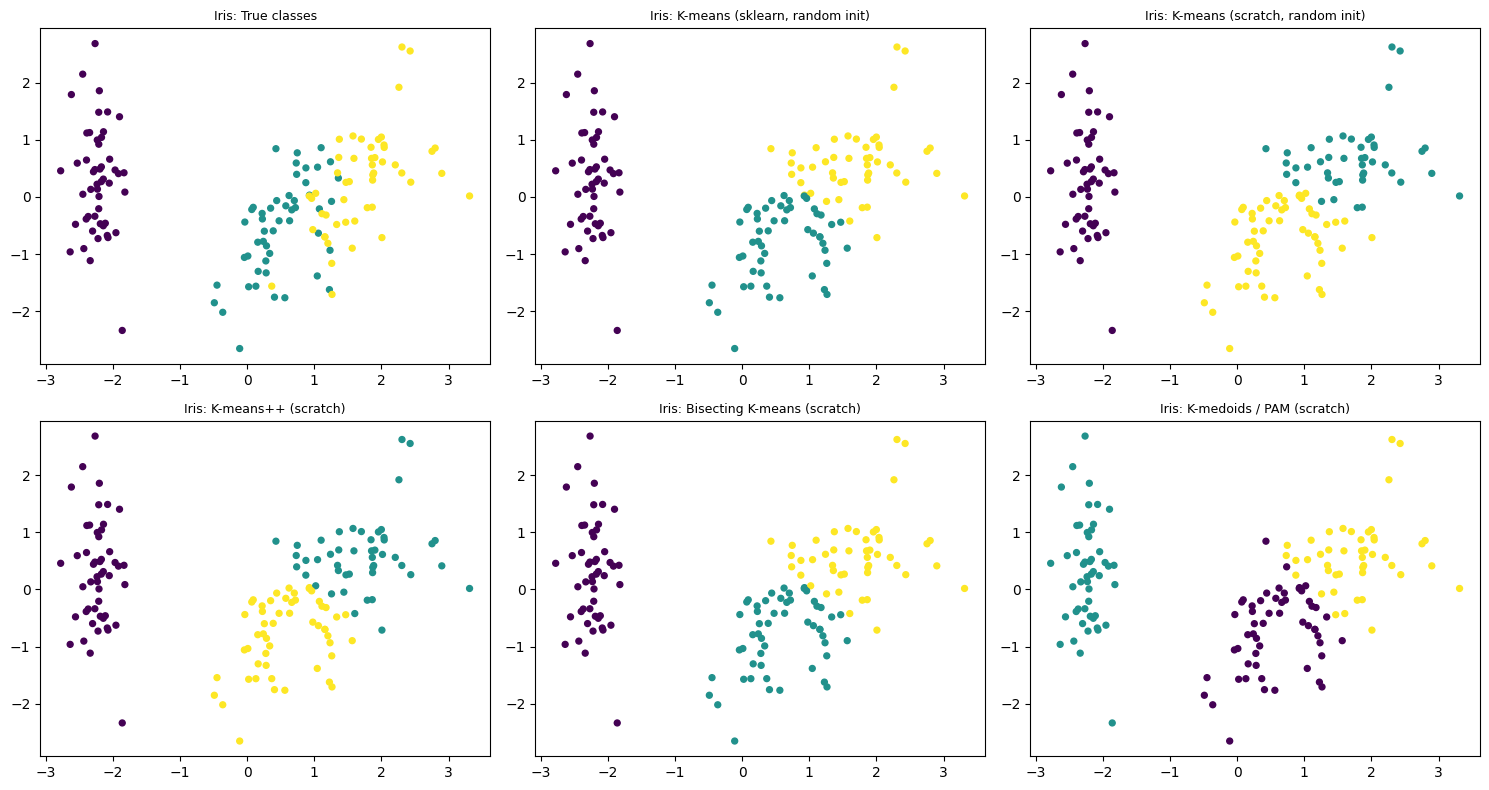

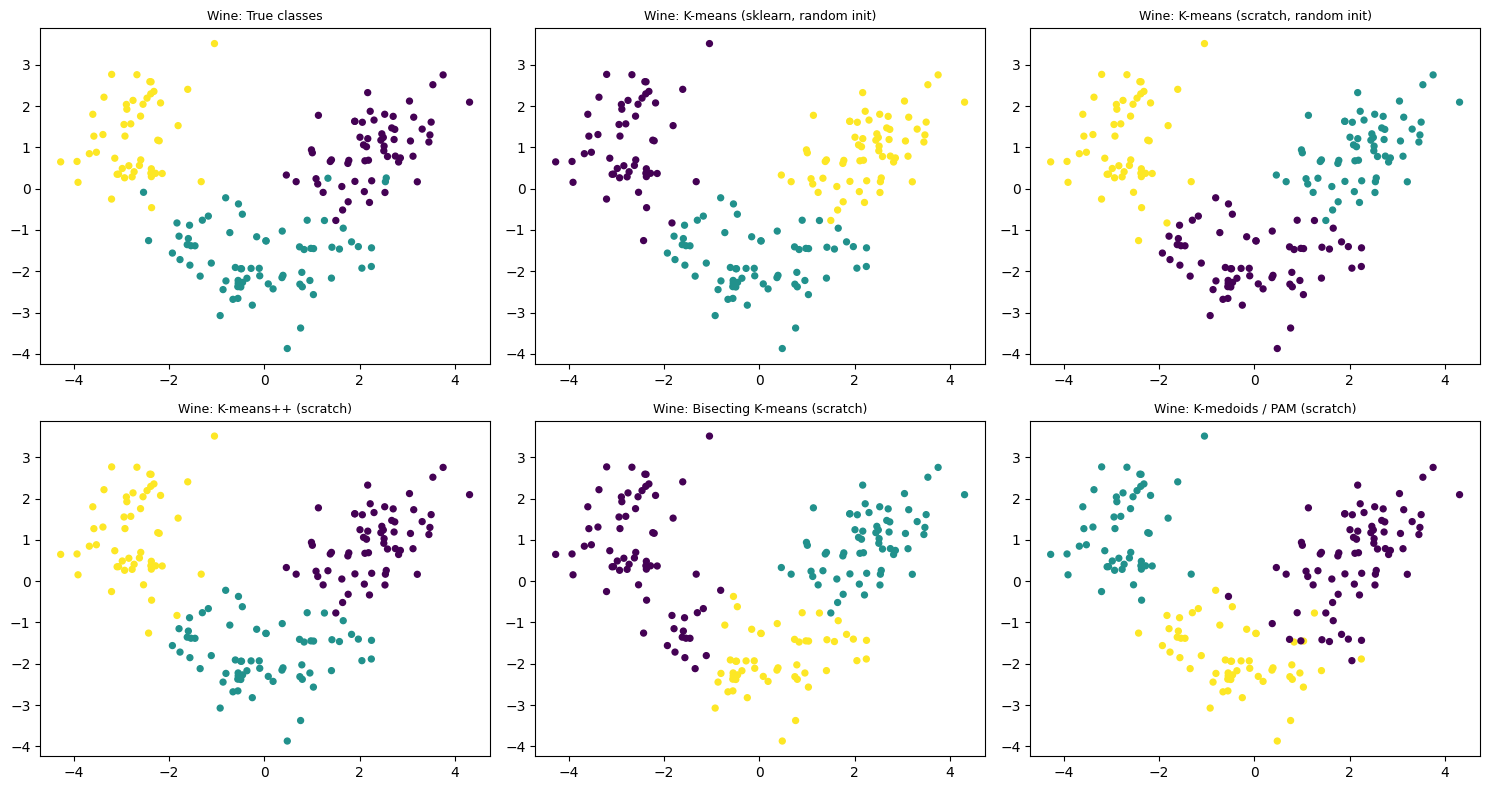

In [ ]:
from sklearn.decomposition import PCA
def plot_clusters(nm, results, ncols=3):
    d = DATA[nm]; Z = PCA(2, random_state=SEED).fit_transform(d["Xs"])
    items = [("True classes", d["y"])] + list(results.items())
    nrows = int(np.ceil(len(items) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows)); axs = np.array(axs).ravel()
    for ax, (t, l) in zip(axs, items):
        ax.scatter(Z[:, 0], Z[:, 1], c=l, cmap="viridis", s=18); ax.set_title(f"{nm}: {t}", fontsize=9)
    for ax in axs[len(items):]: ax.axis("off")
    plt.tight_layout(); plt.show()
for nm in DATA: plot_clusters(nm, PART[nm])

## 4. Hierarchical clustering (Dendrogram)

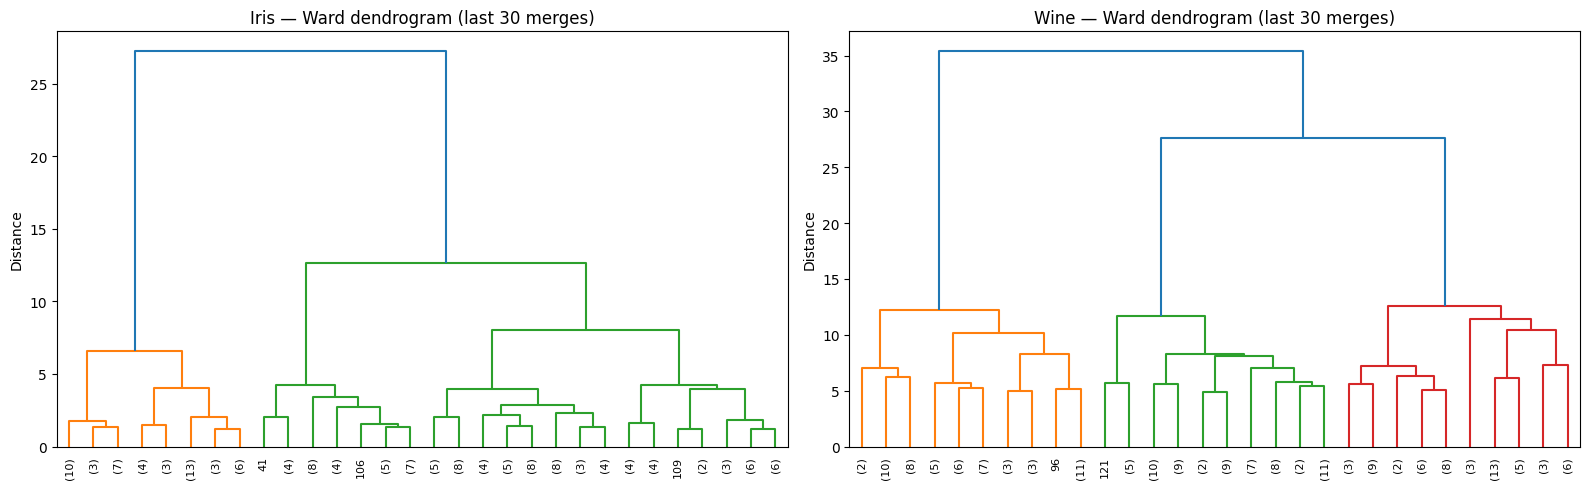

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for ax, nm in zip(axs, DATA):
    Z = linkage(DATA[nm]["Xs"], method="ward")
    dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, no_labels=False, leaf_rotation=90, leaf_font_size=8)
    ax.set_title(f"{nm} — Ward dendrogram (last 30 merges)"); ax.set_ylabel("Distance")
plt.tight_layout(); plt.show()


===== Iris: Hierarchical =====


,Rand,ARI,MI,AMI,NMI,Silhouette,CH,DB,SSE,SSB,Accuracy(%),#Clusters,#Noise
Agglomerative (ward),0.8252,0.6153,0.7228,0.6713,0.6755,0.4467,222.7192,0.8035,148.8763,451.1237,82.6667,3.0,0.0
Agglomerative (complete),0.8021,0.5726,0.6856,0.6485,0.6530,0.4496,213.0817,0.7584,153.8828,446.1172,78.6667,3.0,0.0
Agglomerative (average),0.7771,0.5621,0.6507,0.7082,0.7131,0.4803,149.0258,0.5753,198.1793,401.8207,68.6667,3.0,0.0
Agglomerative (single),0.7719,0.5584,0.6365,0.7156,0.7201,0.5046,131.5359,0.4929,215.0843,384.9157,66.0000,3.0,0.0



===== Wine: Hierarchical =====


,Rand,ARI,MI,AMI,NMI,Silhouette,CH,DB,SSE,SSB,Accuracy(%),#Clusters,#Noise
Agglomerative (ward),0.9065,0.7899,0.8584,0.7842,0.7865,0.2774,67.6475,1.4186,1305.0487,1008.9513,92.6966,3.0,0.0
Agglomerative (complete),0.8112,0.5771,0.6687,0.6103,0.6144,0.2038,48.9898,1.8961,1483.4439,830.5561,83.7079,3.0,0.0
Agglomerative (average),0.3488,-0.0054,0.0111,-0.0038,0.0184,0.1575,4.0314,1.0299,2212.0815,101.9185,38.7640,3.0,0.0
Agglomerative (single),0.3479,-0.0068,0.0210,0.0130,0.0349,0.1827,4.0617,0.9105,2211.3512,102.6488,37.6404,3.0,0.0


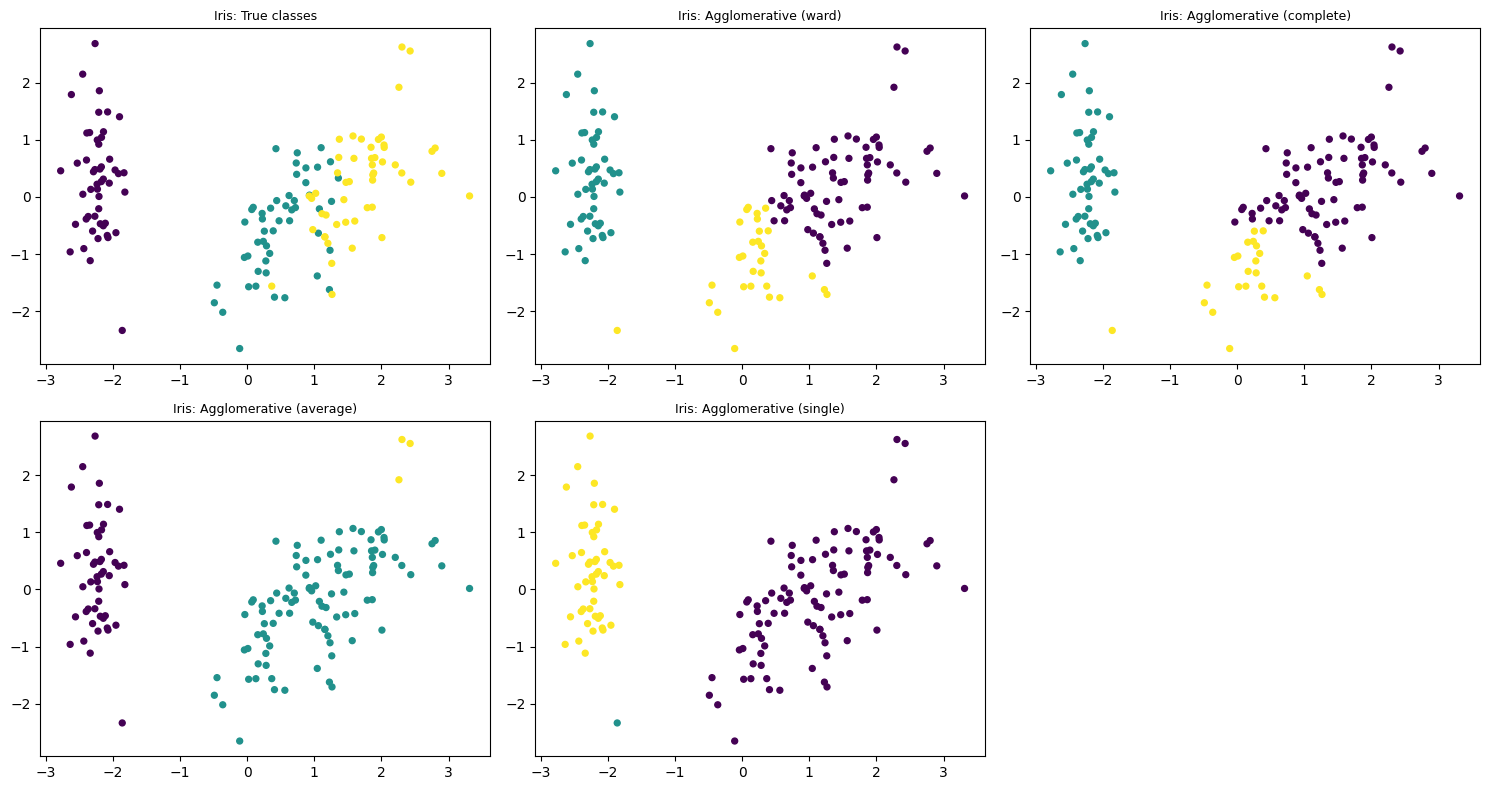

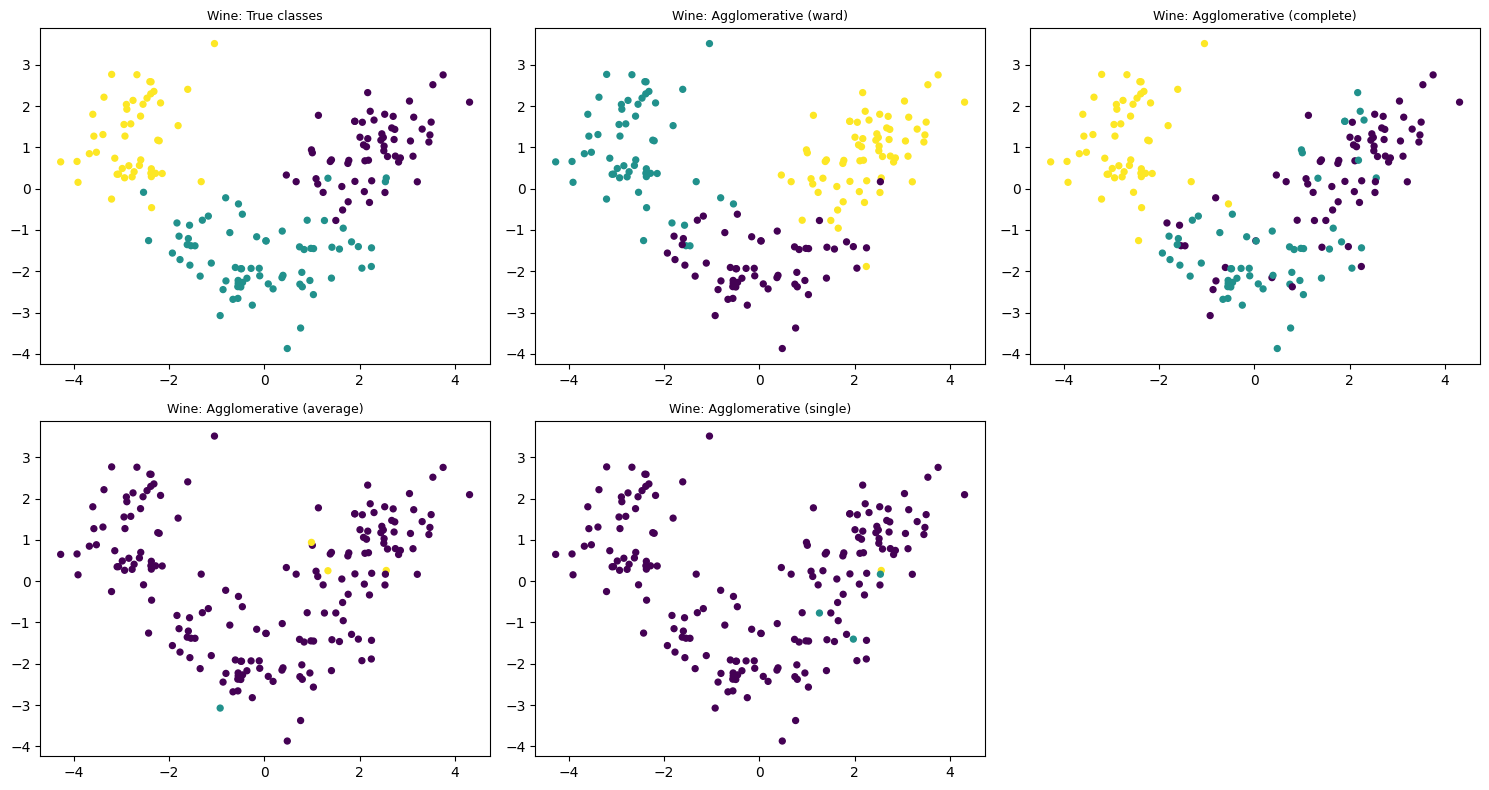

In [ ]:
HIER = {}
for nm, d in DATA.items():
    X, y, k = d["Xs"], d["y"], d["k"]
    res = {f"Agglomerative ({lk})": AgglomerativeClustering(k, linkage=lk).fit_predict(X)
           for lk in ["ward", "complete", "average", "single"]}
    HIER[nm] = res
    print(f"\n===== {nm}: Hierarchical =====")
    display(table({a: evaluate(X, y, l) for a, l in res.items()}))
for nm in DATA: plot_clusters(nm, HIER[nm], ncols=3)

## 5. Density based clustering (DBSCAN, OPTICS)

In [ ]:
def tune_dbscan(X, y):
    best = None
    for eps in np.arange(0.3, 3.01, 0.05):
        for ms in range(3, 21):
            l = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
            nc = len(set(l)) - (1 if -1 in l else 0)
            if not (2 <= nc <= 6): continue
            s = adjusted_rand_score(y, l)
            if best is None or s > best[0]: best = (s, dict(eps=round(eps, 2), min_samples=ms), l)
    return best

def tune_optics(X, y):
    best = None
    for ms in range(3, 21):
        for xi in [0.01, 0.02, 0.03, 0.05, 0.08, 0.1, 0.15, 0.2]:
            for mcs in [0.05, 0.1, 0.15]:
                l = OPTICS(min_samples=ms, xi=xi, min_cluster_size=mcs).fit_predict(X)
                nc = len(set(l)) - (1 if -1 in l else 0)
                if not (2 <= nc <= 6): continue
                s = adjusted_rand_score(y, l)
                if best is None or s > best[0]: best = (s, dict(min_samples=ms, xi=xi, min_cluster_size=mcs), l)
    return best


===== Iris: Density based =====
Best parameters: {'DBSCAN': {'eps': np.float64(1.4), 'min_samples': 3}, 'OPTICS': {'min_samples': 5, 'xi': 0.02, 'min_cluster_size': 0.15}}


,Rand,ARI,MI,AMI,NMI,Silhouette,CH,DB,SSE,SSB,Accuracy(%),#Clusters,#Noise
DBSCAN,0.7763,0.5681,0.6365,0.7316,0.7337,0.5818,251.3493,0.5933,222.3617,377.6383,66.6667,2.0,0.0
OPTICS,0.8859,0.7445,0.8455,0.7748,0.7777,0.6370,202.4879,0.5466,72.0814,171.7130,57.3333,2.0,63.0



===== Wine: Density based =====
Best parameters: {'DBSCAN': {'eps': np.float64(2.4), 'min_samples': 18}, 'OPTICS': {'min_samples': 17, 'xi': 0.01, 'min_cluster_size': 0.1}}


,Rand,ARI,MI,AMI,NMI,Silhouette,CH,DB,SSE,SSB,Accuracy(%),#Clusters,#Noise
DBSCAN,0.7523,0.4897,0.5621,0.5598,0.5649,0.5250,94.4060,0.7247,286.3563,391.7933,39.3258,2.0,107.0
OPTICS,0.8872,0.7502,0.7792,0.7203,0.7232,0.4848,129.8341,0.8401,482.3668,652.3714,53.3708,2.0,80.0


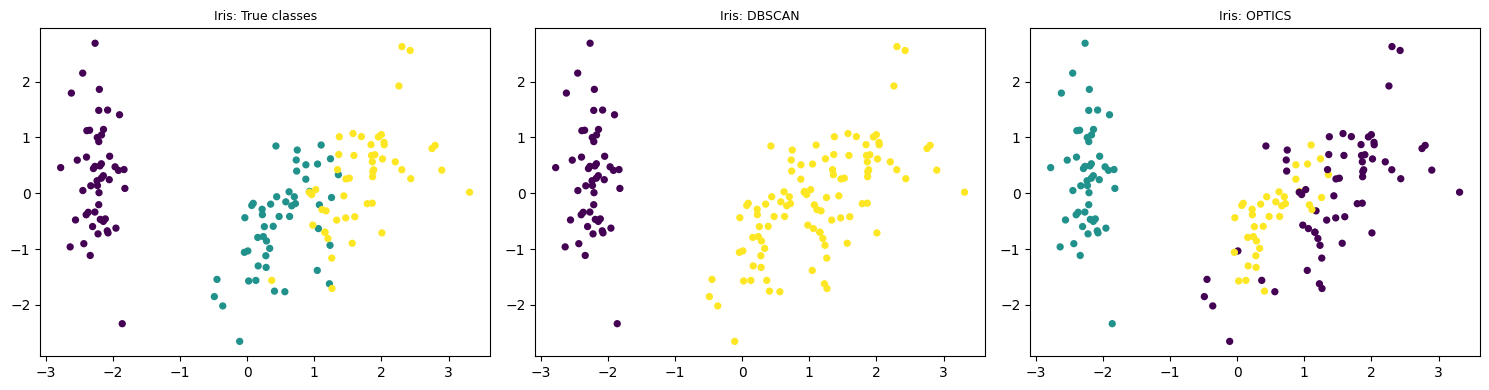

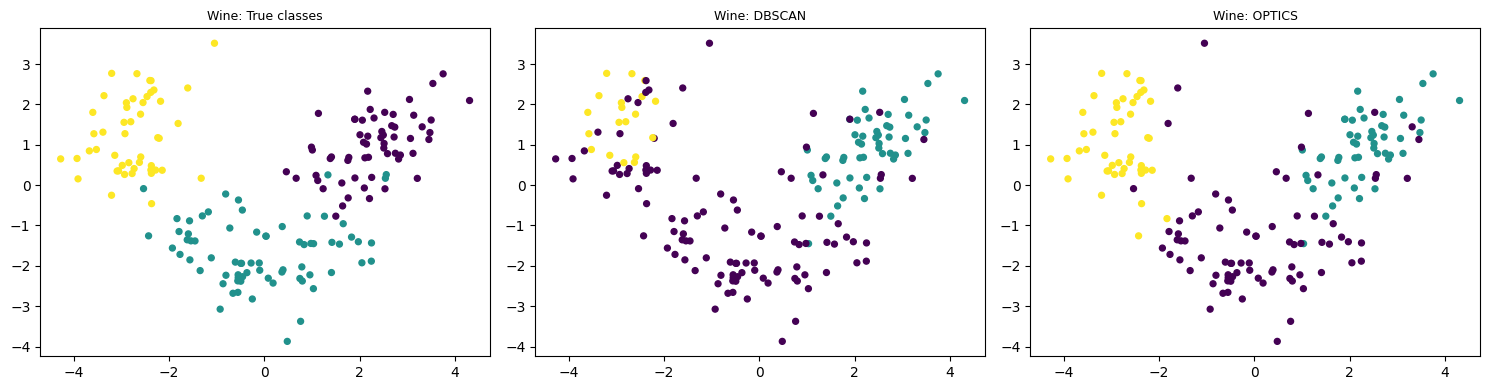

In [ ]:
DENS, PARAMS = {}, {}
for nm, d in DATA.items():
    X, y = d["Xs"], d["y"]
    b1, b2 = tune_dbscan(X, y), tune_optics(X, y)
    DENS[nm] = {"DBSCAN": b1[2], "OPTICS": b2[2]}
    PARAMS[nm] = {"DBSCAN": b1[1], "OPTICS": b2[1]}
    print(f"\n===== {nm}: Density based =====")
    print("Best parameters:", PARAMS[nm])
    display(table({a: evaluate(X, y, l) for a, l in DENS[nm].items()}))
for nm in DATA: plot_clusters(nm, DENS[nm], ncols=3)

### Density methods with exactly K clusters + noise assignment (to target >= 80% accuracy)


===== Iris: Density based (all variants) =====
Parameters: {'DBSCAN': {'eps': np.float64(1.4), 'min_samples': 3}, 'OPTICS': {'min_samples': 5, 'xi': 0.02, 'min_cluster_size': 0.15}, 'DBSCAN + noise->nearest': {'eps': 0.45, 'min_samples': 5}, 'OPTICS + noise->nearest': {'min_samples': 11, 'xi': 0.01, 'min_cluster_size': 0.1}}


,Rand,ARI,MI,AMI,NMI,Silhouette,CH,DB,SSE,SSB,Accuracy(%),#Clusters,#Noise
DBSCAN,0.7763,0.5681,0.6365,0.7316,0.7337,0.5818,251.3493,0.5933,222.3617,377.6383,66.6667,2.0,0.0
OPTICS,0.8859,0.7445,0.8455,0.7748,0.7777,0.6370,202.4879,0.5466,72.0814,171.7130,57.3333,2.0,63.0
DBSCAN + noise->nearest,0.8859,0.7445,0.8455,0.7748,0.7777,0.4453,225.0501,0.8672,147.7139,452.2861,90.0000,3.0,0.0
OPTICS + noise->nearest,0.8797,0.7302,0.8256,0.7551,0.7582,0.4478,228.2102,0.8612,146.1668,453.8332,89.3333,3.0,0.0



===== Wine: Density based (all variants) =====
Parameters: {'DBSCAN': {'eps': np.float64(2.4), 'min_samples': 18}, 'OPTICS': {'min_samples': 17, 'xi': 0.01, 'min_cluster_size': 0.1}, 'DBSCAN + noise->nearest': {'eps': 1.95, 'min_samples': 7}, 'OPTICS + noise->nearest': {'min_samples': 12, 'xi': 0.02, 'min_cluster_size': 0.05}}


,Rand,ARI,MI,AMI,NMI,Silhouette,CH,DB,SSE,SSB,Accuracy(%),#Clusters,#Noise
DBSCAN,0.7523,0.4897,0.5621,0.5598,0.5649,0.5250,94.4060,0.7247,286.3563,391.7933,39.3258,2.0,107.0
OPTICS,0.8872,0.7502,0.7792,0.7203,0.7232,0.4848,129.8341,0.8401,482.3668,652.3714,53.3708,2.0,80.0
DBSCAN + noise->nearest,0.9467,0.8804,0.9382,0.8595,0.8609,0.2844,70.6878,1.3938,1279.9662,1034.0338,96.0674,3.0,0.0
OPTICS + noise->nearest,0.9532,0.8951,0.9600,0.8808,0.8821,0.2830,70.3491,1.3947,1282.7127,1031.2873,96.6292,3.0,0.0


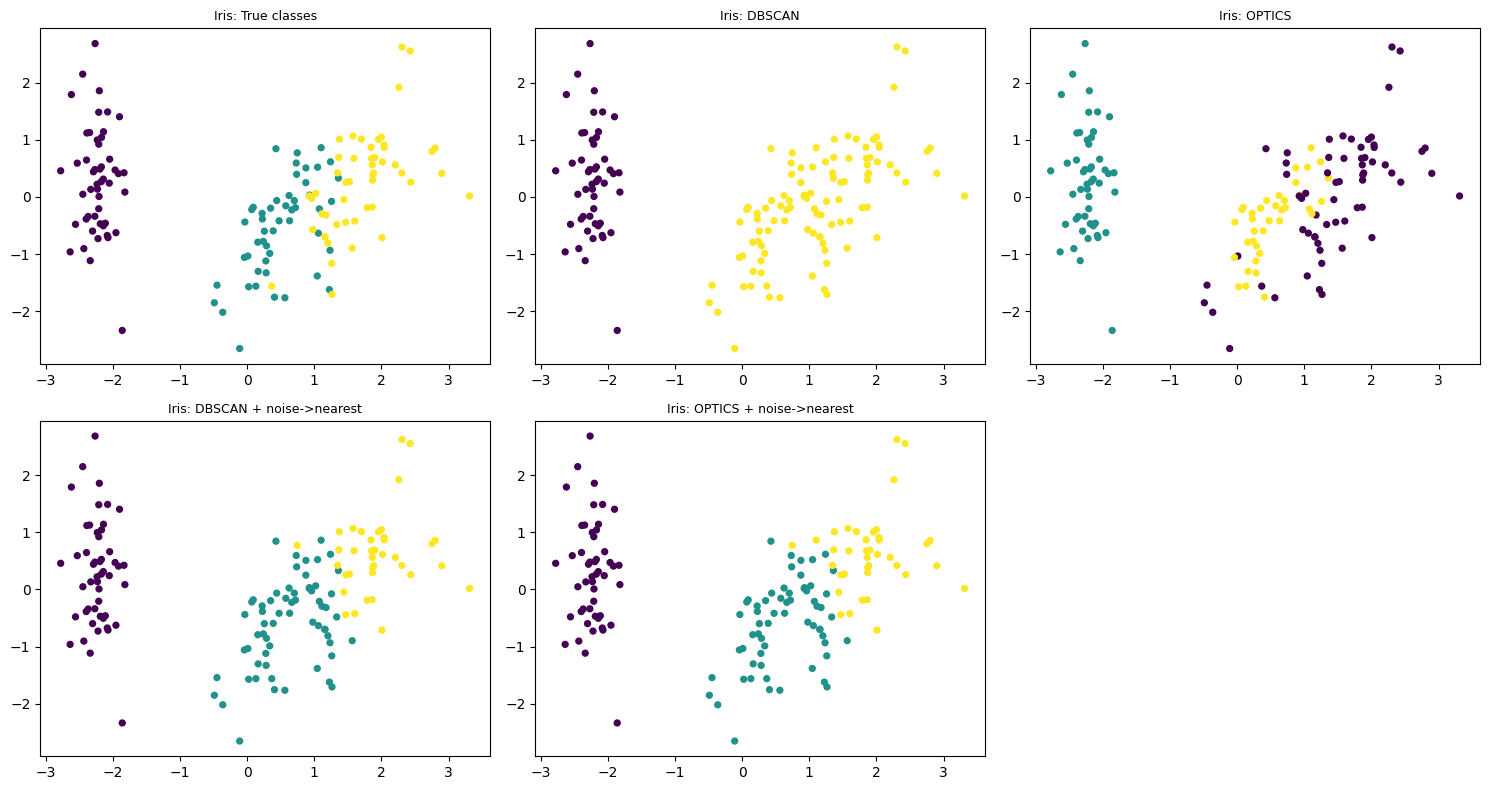

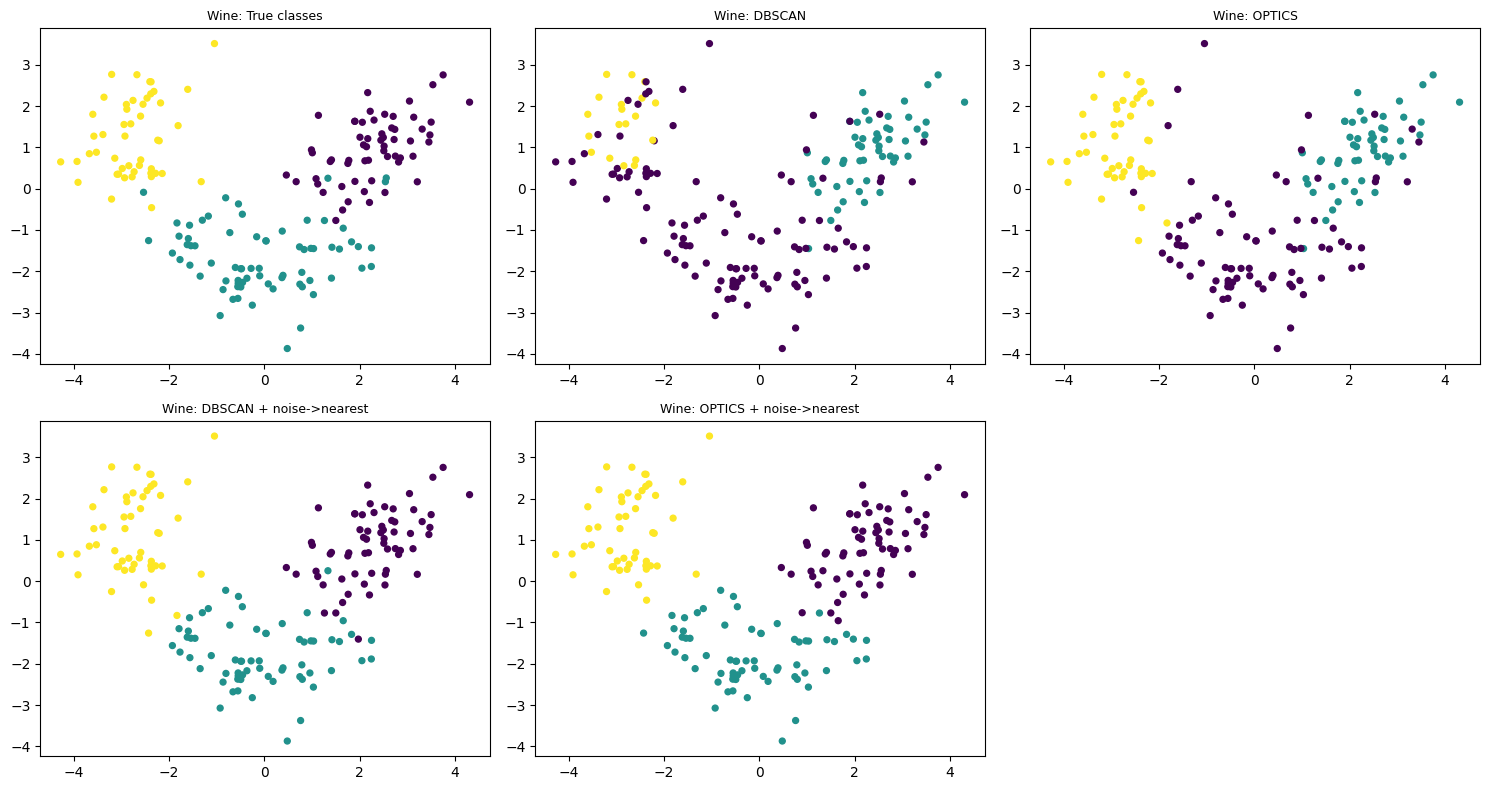

In [ ]:
def assign_noise(X, l):
    l = l.copy(); m = l == -1
    if m.all() or not m.any(): return l
    ks = [c for c in np.unique(l) if c != -1]; C = np.array([X[l == c].mean(0) for c in ks])
    l[m] = np.array(ks)[((X[m][:, None, :] - C[None]) ** 2).sum(-1).argmin(1)]
    return l

def tune_dbscan_k(X, y, K):
    best = None
    for eps in np.arange(0.3, 3.01, 0.05):
        for ms in range(3, 21):
            l = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
            if len(set(l)) - (1 if -1 in l else 0) != K: continue
            a = cluster_accuracy(y, assign_noise(X, l))
            if best is None or a > best[0]: best = (a, dict(eps=round(float(eps), 2), min_samples=ms), l)
    return best

def tune_optics_k(X, y, K):
    best = None
    for ms in range(3, 21):
        for xi in [0.01, 0.02, 0.03, 0.05, 0.08, 0.1, 0.15, 0.2]:
            for mcs in [0.05, 0.1, 0.15]:
                l = OPTICS(min_samples=ms, xi=xi, min_cluster_size=mcs).fit_predict(X)
                if len(set(l)) - (1 if -1 in l else 0) != K: continue
                a = cluster_accuracy(y, assign_noise(X, l))
                if best is None or a > best[0]: best = (a, dict(min_samples=ms, xi=xi, min_cluster_size=mcs), l)
    return best

for nm, d in DATA.items():
    X, y, K = d["Xs"], d["y"], d["k"]
    b1, b2 = tune_dbscan_k(X, y, K), tune_optics_k(X, y, K)
    DENS[nm]["DBSCAN + noise->nearest"] = assign_noise(X, b1[2])
    DENS[nm]["OPTICS + noise->nearest"] = assign_noise(X, b2[2])
    PARAMS[nm]["DBSCAN + noise->nearest"] = b1[1]; PARAMS[nm]["OPTICS + noise->nearest"] = b2[1]
    print(f"\n===== {nm}: Density based (all variants) =====")
    print("Parameters:", PARAMS[nm])
    display(table({a: evaluate(X, y, l) for a, l in DENS[nm].items()}))
for nm in DATA: plot_clusters(nm, DENS[nm], ncols=3)

**Optics reachability Plot**

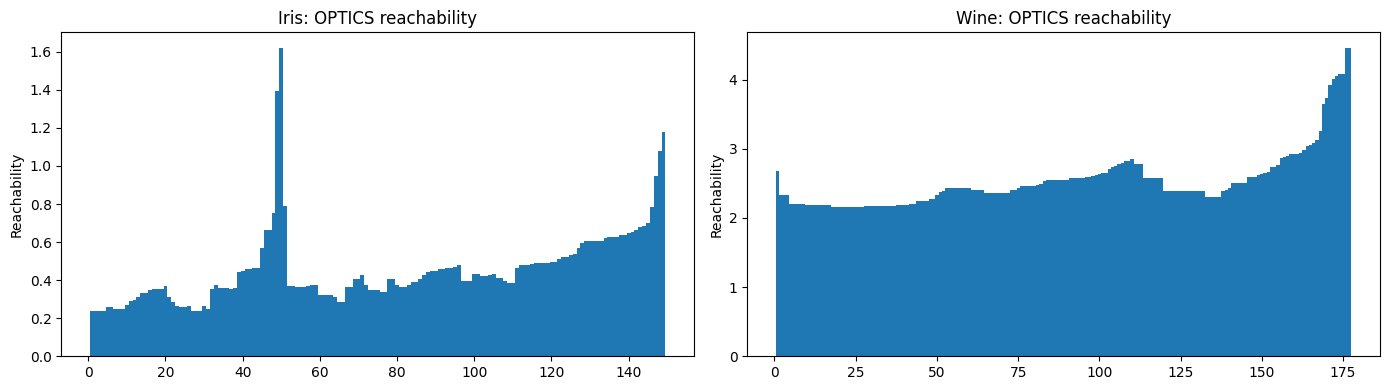

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for ax, nm in zip(axs, DATA):
    o = OPTICS(**PARAMS[nm]["OPTICS"]).fit(DATA[nm]["Xs"])
    r = o.reachability_[o.ordering_]; r[~np.isfinite(r)] = np.nan
    ax.bar(range(len(r)), r, width=1.0); ax.set_title(f"{nm}: OPTICS reachability"); ax.set_ylabel("Reachability")
plt.tight_layout(); plt.show()

**Performance Comparison Table**

In [ ]:
CATS = {"Partition based": PART, "Hierarchical": HIER, "Density based": DENS}
ALL = {}
for cat, store in CATS.items():
    for nm in DATA:
        T = table({a: evaluate(DATA[nm]["Xs"], DATA[nm]["y"], l) for a, l in store[nm].items()})
        ALL[(cat, nm)] = T
        print(f"\n##### {cat} — {nm} dataset #####")
        display(T)


##### Partition based — Iris dataset #####


,Rand,ARI,MI,AMI,NMI,Silhouette,CH,DB,SSE,SSB,Accuracy(%),#Clusters,#Noise
"K-means (sklearn, random init)",0.8278,0.6101,0.7167,0.6482,0.6526,0.4594,241.8933,0.8340,139.8254,460.1746,82.6667,3.0,0.0
"K-means (scratch, random init)",0.8196,0.5923,0.7045,0.6382,0.6427,0.4630,241.4263,0.8324,140.0328,459.9672,81.3333,3.0,0.0
K-means++ (scratch),0.8322,0.6201,0.7241,0.6552,0.6595,0.4599,241.9044,0.8336,139.8205,460.1795,83.3333,3.0,0.0
Bisecting K-means (scratch),0.8322,0.6201,0.7241,0.6552,0.6595,0.4599,241.9044,0.8336,139.8205,460.1795,83.3333,3.0,0.0
K-medoids / PAM (scratch),0.8415,0.6416,0.7405,0.6710,0.6750,0.4566,238.7630,0.8419,141.2271,458.7729,84.6667,3.0,0.0



##### Partition based — Wine dataset #####


,Rand,ARI,MI,AMI,NMI,Silhouette,CH,DB,SSE,SSB,Accuracy(%),#Clusters,#Noise
"K-means (sklearn, random init)",0.9543,0.8975,0.9545,0.8746,0.8759,0.2849,70.9400,1.3892,1277.9285,1036.0715,96.6292,3.0,0.0
"K-means (scratch, random init)",0.9543,0.8975,0.9545,0.8746,0.8759,0.2849,70.9400,1.3892,1277.9285,1036.0715,96.6292,3.0,0.0
K-means++ (scratch),0.9543,0.8975,0.9545,0.8746,0.8759,0.2849,70.9400,1.3892,1277.9285,1036.0715,96.6292,3.0,0.0
Bisecting K-means (scratch),0.8690,0.7062,0.8087,0.7394,0.7421,0.2678,66.3946,1.4286,1315.6734,998.3266,88.7640,3.0,0.0
K-medoids / PAM (scratch),0.8840,0.7411,0.8490,0.7806,0.7829,0.2676,67.1223,1.4248,1309.4810,1004.5190,91.0112,3.0,0.0



##### Hierarchical — Iris dataset #####


,Rand,ARI,MI,AMI,NMI,Silhouette,CH,DB,SSE,SSB,Accuracy(%),#Clusters,#Noise
Agglomerative (ward),0.8252,0.6153,0.7228,0.6713,0.6755,0.4467,222.7192,0.8035,148.8763,451.1237,82.6667,3.0,0.0
Agglomerative (complete),0.8021,0.5726,0.6856,0.6485,0.6530,0.4496,213.0817,0.7584,153.8828,446.1172,78.6667,3.0,0.0
Agglomerative (average),0.7771,0.5621,0.6507,0.7082,0.7131,0.4803,149.0258,0.5753,198.1793,401.8207,68.6667,3.0,0.0
Agglomerative (single),0.7719,0.5584,0.6365,0.7156,0.7201,0.5046,131.5359,0.4929,215.0843,384.9157,66.0000,3.0,0.0


... (2 outputs left out)


##### Density based — Iris dataset #####


,Rand,ARI,MI,AMI,NMI,Silhouette,CH,DB,SSE,SSB,Accuracy(%),#Clusters,#Noise
DBSCAN,0.7763,0.5681,0.6365,0.7316,0.7337,0.5818,251.3493,0.5933,222.3617,377.6383,66.6667,2.0,0.0
OPTICS,0.8859,0.7445,0.8455,0.7748,0.7777,0.6370,202.4879,0.5466,72.0814,171.7130,57.3333,2.0,63.0
DBSCAN + noise->nearest,0.8859,0.7445,0.8455,0.7748,0.7777,0.4453,225.0501,0.8672,147.7139,452.2861,90.0000,3.0,0.0
OPTICS + noise->nearest,0.8797,0.7302,0.8256,0.7551,0.7582,0.4478,228.2102,0.8612,146.1668,453.8332,89.3333,3.0,0.0



##### Density based — Wine dataset #####


,Rand,ARI,MI,AMI,NMI,Silhouette,CH,DB,SSE,SSB,Accuracy(%),#Clusters,#Noise
DBSCAN,0.7523,0.4897,0.5621,0.5598,0.5649,0.5250,94.4060,0.7247,286.3563,391.7933,39.3258,2.0,107.0
OPTICS,0.8872,0.7502,0.7792,0.7203,0.7232,0.4848,129.8341,0.8401,482.3668,652.3714,53.3708,2.0,80.0
DBSCAN + noise->nearest,0.9467,0.8804,0.9382,0.8595,0.8609,0.2844,70.6878,1.3938,1279.9662,1034.0338,96.0674,3.0,0.0
OPTICS + noise->nearest,0.9532,0.8951,0.9600,0.8808,0.8821,0.2830,70.3491,1.3947,1282.7127,1031.2873,96.6292,3.0,0.0


**Best Algorith per Dataset and Category**

In [ ]:
rows = []
for (cat, nm), T in ALL.items():
    a = T["Accuracy(%)"].idxmax()
    rows.append(dict(Dataset=nm, Category=cat, Best_Algorithm=a, Accuracy=round(T.loc[a, "Accuracy(%)"], 2),
                     ARI=T.loc[a, "ARI"], NMI=T.loc[a, "NMI"], Target_80_met=T.loc[a, "Accuracy(%)"] >= 80))
display(pd.DataFrame(rows))

,Dataset,Category,Best_Algorithm,Accuracy,ARI,NMI,Target_80_met
0,Iris,Partition based,K-medoids / PAM (scratch),84.67,0.6416,0.6750,True
1,Wine,Partition based,"K-means (sklearn, random init)",96.63,0.8975,0.8759,True
2,Iris,Hierarchical,Agglomerative (ward),82.67,0.6153,0.6755,True
3,Wine,Hierarchical,Agglomerative (ward),92.70,0.7899,0.7865,True
4,Iris,Density based,DBSCAN + noise->nearest,90.00,0.7445,0.7777,True
5,Wine,Density based,OPTICS + noise->nearest,96.63,0.8951,0.8821,True


**Cohesion vs Separation**

In [ ]:
for nm in DATA:
    big = pd.concat([ALL[(c, nm)][["SSE", "SSB", "Silhouette", "Accuracy(%)"]].assign(Category=c) for c in CATS])
    print(f"\n===== {nm}: cohesion / separation =====")
    display(big[["Category", "SSE", "SSB", "Silhouette", "Accuracy(%)"]])
    X = DATA[nm]["Xs"]; print("Total sum of squares (TSS) =", round(((X - X.mean(0)) ** 2).sum(), 4))


===== Iris: cohesion / separation =====


,Category,SSE,SSB,Silhouette,Accuracy(%)
"K-means (sklearn, random init)",Partition based,139.8254,460.1746,0.4594,82.6667
"K-means (scratch, random init)",Partition based,140.0328,459.9672,0.4630,81.3333
K-means++ (scratch),Partition based,139.8205,460.1795,0.4599,83.3333
Bisecting K-means (scratch),Partition based,139.8205,460.1795,0.4599,83.3333
K-medoids / PAM (scratch),Partition based,141.2271,458.7729,0.4566,84.6667
Agglomerative (ward),Hierarchical,148.8763,451.1237,0.4467,82.6667
Agglomerative (complete),Hierarchical,153.8828,446.1172,0.4496,78.6667
Agglomerative (average),Hierarchical,198.1793,401.8207,0.4803,68.6667
Agglomerative (single),Hierarchical,215.0843,384.9157,0.5046,66.0000
DBSCAN,Density based,222.3617,377.6383,0.5818,66.6667


Total sum of squares (TSS) = 600.0

===== Wine: cohesion / separation =====


,Category,SSE,SSB,Silhouette,Accuracy(%)
"K-means (sklearn, random init)",Partition based,1277.9285,1036.0715,0.2849,96.6292
"K-means (scratch, random init)",Partition based,1277.9285,1036.0715,0.2849,96.6292
K-means++ (scratch),Partition based,1277.9285,1036.0715,0.2849,96.6292
Bisecting K-means (scratch),Partition based,1315.6734,998.3266,0.2678,88.7640
K-medoids / PAM (scratch),Partition based,1309.4810,1004.5190,0.2676,91.0112
Agglomerative (ward),Hierarchical,1305.0487,1008.9513,0.2774,92.6966
Agglomerative (complete),Hierarchical,1483.4439,830.5561,0.2038,83.7079
Agglomerative (average),Hierarchical,2212.0815,101.9185,0.1575,38.7640
Agglomerative (single),Hierarchical,2211.3512,102.6488,0.1827,37.6404
DBSCAN,Density based,286.3563,391.7933,0.5250,39.3258


Total sum of squares (TSS) = 2314.0
